# Notebook 6: Block cellular Automata and their Spectral analysis
The aim of the first part of the notebook is not to keep building upon the fucntions defined earlier, but pause for a second and use the functions defined in the past to simulate 1-d wave interference.

The aim of the second part is to define block Cellular Automata and explain why they are so useful for simulating problems in physics.

In [1]:
import numpy as np

from itertools import permutations, product

In [2]:
from Functions_for_Notebook_1 import make_rule, make_rule_zero_condition, make_rule_symmetry #For making the rules

from Functions_for_Notebook_1 import dynamics, dynamics_reflection, dynamics_periodic #For the dynamics

from Functions_for_Notebook_1 import plot_grid #For the plotting

## 4.1) Exploring causality bounds in elementary CA grids
In special relativity, the light cone of an event is the set of spacetime points reachable by signals at speed $c$, the surface $c^2\Delta t^2 = \Delta x^2+\Delta y^2+\Delta z^2$. It divides spacetime into three regions relative to the event:

Future cone: events it can influence.
Past cone: events that can influence it.
Elsewhere: spacelike-separated events, causally disconnected from it in both directions.

Because the interval $c^2\Delta t^2-\Delta\mathbf{x}^2$ is invariant under Lorentz transformations, all inertial observers agree on the cone. They agree on which events are causally ordered even when they disagree about simultaneity for spacelike pairs.

This same concept can be encounteres in the 2-d lattice showing the evolution of a classical CA through its discrete timesteps. The CA cone plays the same causal role, with $c=1$ cell/step, because only a neighboring cell can affect anotehr cell. The difference is that it’s fixed by the lattice: there are no boosts that preserve it, so it is a causal structure without Lorentz symmetry.

https://arxiv.org/html/2602.20623v1

These limits in the propagation of information inside the system will also include damage and entropy of the system. So each given system will have a maximum lyapunov exponent and Shannon entropy capped by this causal effect.

For cell i, cell i at t+1 is a fucntion of cell i-r and cell i+r. In the case of elementary CA, r = 1.

### 4.1.1) Lyapunov exponent capped by causality
For t timesteps, cell i will be a fucntion of cell i-rt and cell i+rt, so cell i-t and i+t.

### 4.1.2) Shannon entropy capped by causality

## 4.2) Recreating classical particle collision with rule 54

Rule 54 is a specially relevant rule for physics, it is a class IV rule that produces the following shapes:
- 

## 4.3) (Classical) Block Cellular Automata
### 4.3.1) How their evolution works
Block cellular Automata are a special type of CA that fixes the irreversibility issue of ordinary CA by construction.

In ordinary CA, each cell of the grid is updated individually given a the rule. In block CA, the lattice is divided into non-overlapping regions and the rule is applied to each region. In order to apply a rule to a region, you choose form a permutation and because permutattions are invertible, then the system is always invertible. An example, for blocks consising of two cells, would be the following:

{00,01,10,11}→{11,10,01,00}

### 4.3.2) Different types of evolution (blocks of 2)
Any evolution can be defined and its reversibility will depend on its construction, though all permutations will be reversible. There are examples of evolutions that are used frequently:
- identity: (a,b)→(a,b) 
- SWAP: (a,b)→(b,a) 
- XOR-into-first: (a,b)→(a⊕b, b)
- NOT-both: (a,b)→(¬a,¬b)

### 4.3.3) Different partition schemes 
In one dimension, the partition schemes comes down only to how many cells you include in each segment. For now, only one dimensional block CA are looked at.

In [3]:
def identity_n(block):
    return block

def swap2(block):
    a, b = block
    return (b, a)

def xor_into_first(block):
    a, b = block
    return (a ^ b, b)

def not_both(block):
    a, b = block
    return (1 - a, 1 - b)

### 4.3.4) Different types of evolution (blocks of 3)
The following are the most common cases of evolution for segmets of 3 cells:

In [4]:
def identity3(block):
    return block

def shift_right3(block):          # cyclic: (a,b,c) -> (c,a,b)
    a, b, c = block
    return (c, a, b)

def shift_left3(block):           # cyclic: (a,b,c) -> (b,c,a)
    a, b, c = block
    return (b, c, a)

def reverse3(block):              # mirror the block: swap ends
    a, b, c = block
    return (c, b, a)

def not_all3(block):
    a, b, c = block
    return (1 - a, 1 - b, 1 - c)

def toffoli(block):               # CCNOT: flip c iff a = b = 1
    a, b, c = block
    return (a, b, c ^ (a & b))

def fredkin(block):               # controlled swap: swap b,c iff a = 1
    a, b, c = block
    return (a, c, b) if a else (a, b, c)

def cnot_chain3(block):           # b ^= a, then c ^= b 
    a, b, c = block
    b = b ^ a
    c = c ^ b
    return (a, b, c)

### 4.3.5) Different types of evolution (blocks of 4)
The following are the most common cases of evolution for segmets of 4 cells:

In [5]:
def identity4(block):
    return block

def shift_right4(block):          # cyclic: (a,b,c,d) -> (d,a,b,c)
    a, b, c, d = block
    return (d, a, b, c)

def shift_left4(block):           # cyclic: (a,b,c,d) -> (b,c,d,a)
    a, b, c, d = block
    return (b, c, d, a)

def reverse4(block):              # mirror the block
    a, b, c, d = block
    return (d, c, b, a)

def pair_swap4(block):            # swap within each half: two swap2's
    a, b, c, d = block
    return (b, a, d, c)

def half_swap4(block):            # swap the two halves
    a, b, c, d = block
    return (c, d, a, b)

def not_all4(block):
    a, b, c, d = block
    return (1 - a, 1 - b, 1 - c, 1 - d)

def toffoli4(block):              # CCCNOT: flip d iff a = b = c = 1
    a, b, c, d = block
    return (a, b, c, d ^ (a & b & c))

def fredkin4(block):              # a controls swap of (b,c); d passive
    a, b, c, d = block
    return (a, c, b, d) if a else (a, b, c, d)

def cnot_chain4(block):           # b ^= a, c ^= b, d ^= c  
    a, b, c, d = block
    b ^= a; c ^= b; d ^= c
    return (a, b, c, d)

def rotate2x2(block):             # read block as 2x2 [[a,b],[c,d]], rotate 90° clockwise
    a, b, c, d = block
    return (c, a, d, b)

### 4.3.6) Coding the dynamics

In [6]:
def block_dynamics(initial_conditions, L, block_map, n_steps, block_size=2):
    assert L % block_size == 0, "L must be divisible by block_size"

    state = np.zeros(L, dtype=int)
    state[np.asarray(initial_conditions, dtype=int)] = 1

    grid = np.empty((n_steps + 1, L), dtype=int)
    grid[0] = state

    for t in range(n_steps):
        offset = t % block_size
        new_state = state.copy()
        for i in range(offset, L, block_size):
            idx = [(i + k) % L for k in range(block_size)]
            block_in = tuple(state[idx])
            block_out = block_map(block_in)
            for pos, val in zip(idx, block_out):
                new_state[pos] = val
        state = new_state
        grid[t + 1] = state

    return grid[::-1] # because the output is a numpy grid, then plotting will work with the functions defined earlier

Now, we will define the block_map possibilities:

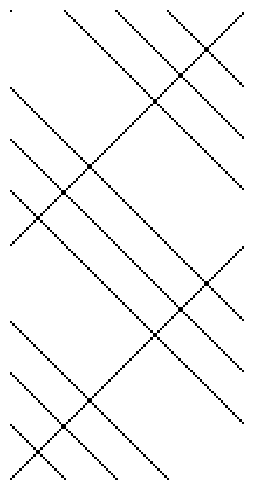

In [7]:
system = block_dynamics([0,45,67,23], 100, swap2, 200)

plot_grid(system)

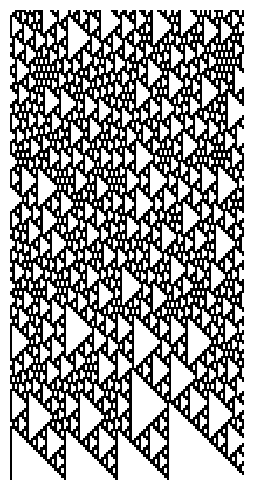

In [8]:
system = block_dynamics([0,45,67,23], 100, xor_into_first, 200)

plot_grid(system)

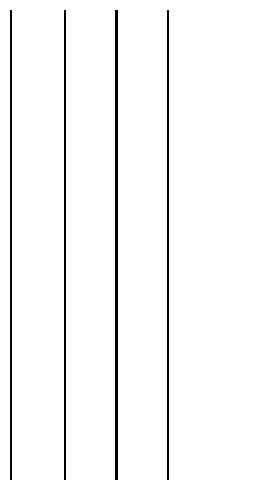

In [9]:
system = block_dynamics([0,45,67,23], 100, identity_n, 200)

plot_grid(system)

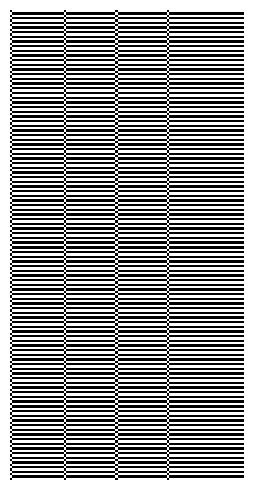

In [10]:
system = block_dynamics([0,45,67,23], 100, not_both, 200)

plot_grid(system)

### 4.2.5) Modeling the dynamics of classical block Cellular Automata with matrices 

The dynamics will now be computed in terms of matrix vector multiplication. Like in elementary CA, this method is too computationally expensive for bigger lattices, but a spectral analysis of the matrix describing the evolution of the system can shed useful information on the system.

The first function that will be defined is _bits. Bits defines all the possible configuration in lattice of length L. It will be the object multiplied by the transition vector to give the dynamics.

In [11]:
import numpy as np
import scipy.sparse as sp

def _bits(L):
    """(2^L, L) bit table; cell 0 = MSB."""
    return (np.arange(2**L)[:, None] >> np.arange(L - 1, -1, -1)) & 1

for i in range(3, 10):
    print(_bits(i))

[[0 0 0]
 [0 0 1]
 [0 1 0]
 [0 1 1]
 [1 0 0]
 [1 0 1]
 [1 1 0]
 [1 1 1]]
[[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]
[[0 0 0 0 0]
 [0 0 0 0 1]
 [0 0 0 1 0]
 [0 0 0 1 1]
 [0 0 1 0 0]
 [0 0 1 0 1]
 [0 0 1 1 0]
 [0 0 1 1 1]
 [0 1 0 0 0]
 [0 1 0 0 1]
 [0 1 0 1 0]
 [0 1 0 1 1]
 [0 1 1 0 0]
 [0 1 1 0 1]
 [0 1 1 1 0]
 [0 1 1 1 1]
 [1 0 0 0 0]
 [1 0 0 0 1]
 [1 0 0 1 0]
 [1 0 0 1 1]
 [1 0 1 0 0]
 [1 0 1 0 1]
 [1 0 1 1 0]
 [1 0 1 1 1]
 [1 1 0 0 0]
 [1 1 0 0 1]
 [1 1 0 1 0]
 [1 1 0 1 1]
 [1 1 1 0 0]
 [1 1 1 0 1]
 [1 1 1 1 0]
 [1 1 1 1 1]]
[[0 0 0 0 0 0]
 [0 0 0 0 0 1]
 [0 0 0 0 1 0]
 [0 0 0 0 1 1]
 [0 0 0 1 0 0]
 [0 0 0 1 0 1]
 [0 0 0 1 1 0]
 [0 0 0 1 1 1]
 [0 0 1 0 0 0]
 [0 0 1 0 0 1]
 [0 0 1 0 1 0]
 [0 0 1 0 1 1]
 [0 0 1 1 0 0]
 [0 0 1 1 0 1]
 [0 0 1 1 1 0]
 [0 0 1 1 1 1]
 [0 1 0 0 0 0]
 [0 1 0 0 0 1]
 [0 1 0 0 1 0]
 [0 1 0 0 1 1]
 [0 1 0 1 0 0]
 [0 1 0 1 0 1]
 [0

The second function defined is _codes. _codes is the inverse of _bits. This fucntion will take the product between the matrics and _bits objects and return it as a 1-d lattice of length L.

In [12]:
def _codes(X):
    return X @ (1 << np.arange(X.shape[-1] - 1, -1, -1))

The third function defined is block_matrix. This function gives the markov chain that descrbes the evolution of the block CA, also by creating a 2^b × 2^b transition matrix, with its same constraints as for ECA and probabilistic ECA.

In [13]:
def block_matrix(block_map, b=2): # This describes the evolution of an individuals segment
    """Column-stochastic P[out, in] (2^b x 2^b) from a callable or an array."""
    if callable(block_map):
        out = np.array([block_map(tuple(int(x) for x in r)) for r in _bits(b)], dtype=int)
        P = np.zeros((2**b, 2**b))
        P[_codes(out), np.arange(2**b)] = 1.0
    else:
        P = np.asarray(block_map, dtype=float)
    assert P.shape == (2**b, 2**b) and np.allclose(P.sum(0), 1), "P must be column-stochastic"
    return P

print(block_matrix(swap2)) # One can see it is doubly-stochastic

[[1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]]


The fourth function is block_layer_matrix and this function

In [14]:
def block_layer_matrix(block_map, L, offset, b=2): # This decribes the evolution of the global dynamics
    """Markov matrix of one partition layer. M[i, j] = P(j -> i)."""
    assert L % b == 0, "L must be divisible by b"
    P = sp.csr_matrix(block_matrix(block_map, b)) # Split latttice into even sections
    K = P
    for _ in range(L // b - 1):
        K = sp.kron(K, P, format="csr")             # offset-0 layer
    r = _codes(np.roll(_bits(L), -offset, axis=1))  # state x -> roll(x, -offset)
    return K[r][:, r]                               # R^T K R, no matmul needed

print(block_layer_matrix(shift_right3, 9, 3, 3))

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 512 stored elements and shape (512, 512)>
  Coords	Values
  (0, 0)	1.0
  (1, 2)	1.0
  (2, 4)	1.0
  (3, 6)	1.0
  (4, 1)	1.0
  (5, 3)	1.0
  (6, 5)	1.0
  (7, 7)	1.0
  (8, 16)	1.0
  (9, 18)	1.0
  (10, 20)	1.0
  (11, 22)	1.0
  (12, 17)	1.0
  (13, 19)	1.0
  (14, 21)	1.0
  (15, 23)	1.0
  (16, 32)	1.0
  (17, 34)	1.0
  (18, 36)	1.0
  (19, 38)	1.0
  (20, 33)	1.0
  (21, 35)	1.0
  (22, 37)	1.0
  (23, 39)	1.0
  (24, 48)	1.0
  :	:
  (487, 463)	1.0
  (488, 472)	1.0
  (489, 474)	1.0
  (490, 476)	1.0
  (491, 478)	1.0
  (492, 473)	1.0
  (493, 475)	1.0
  (494, 477)	1.0
  (495, 479)	1.0
  (496, 488)	1.0
  (497, 490)	1.0
  (498, 492)	1.0
  (499, 494)	1.0
  (500, 489)	1.0
  (501, 491)	1.0
  (502, 493)	1.0
  (503, 495)	1.0
  (504, 504)	1.0
  (505, 506)	1.0
  (506, 508)	1.0
  (507, 510)	1.0
  (508, 505)	1.0
  (509, 507)	1.0
  (510, 509)	1.0
  (511, 511)	1.0


All previous functions come together to define a funtion that describes the dynamics of deterministic block CA through matrix-vector multiplication:

In [15]:
def matrix_block_dynamics(initial_conditions, L, block_map, n_steps, b=2):
    """Block CA evolved by matrix-vector products on the one-hot state vector.
    Same order conventions as all the other dynamics functions."""
    layers = [block_layer_matrix(block_map, L, o, b) for o in range(b)]
    X = _bits(L)

    x = np.zeros(L, dtype=int)
    x[np.asarray(initial_conditions, dtype=int)] = 1
    v = np.zeros(2**L, dtype=int)
    v[_codes(x)] = 1                                # one-hot state vector

    grid = np.empty((n_steps + 1, L), dtype=int)
    grid[0] = x
    for t in range(n_steps):
        v = layers[t % b] @ v
        grid[t + 1] = X[np.argmax(v)]               # index of the 1 -> configuration
    return grid[::-1]

print(matrix_block_dynamics([0,1,2,3], 10, xor_into_first, 10))

[[0 1 0 0 1 0 1 0 0 1]
 [0 1 0 1 1 1 1 0 0 1]
 [1 1 1 1 0 1 1 0 1 1]
 [1 0 1 1 0 0 1 1 1 0]
 [1 0 0 1 0 0 0 1 1 0]
 [1 0 0 1 0 0 0 0 1 1]
 [1 0 1 1 0 0 0 0 0 1]
 [1 1 1 1 0 0 0 0 0 0]
 [0 1 0 1 0 0 0 0 0 0]
 [0 1 0 1 0 0 0 0 0 0]
 [1 1 1 1 0 0 0 0 0 0]]


In [16]:
g = matrix_block_dynamics([0, 3], 10, swap2, 40)
print(g.shape)   # (41, 10)
print(g[-3:])    # t = 0, 1, 2 (reversed order: last rows = earliest times)
print(g)

(41, 10)
[[0 1 1 0 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 0 0 0]
 [1 0 0 1 0 0 0 0 0 0]]
[[1 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 1]
 [0 0 0 0 0 1 0 0 1 0]
 [0 0 0 0 0 0 1 1 0 0]
 [0 0 0 0 0 0 1 1 0 0]
 [0 0 0 0 0 1 0 0 1 0]
 [0 0 0 0 1 0 0 0 0 1]
 [1 0 0 1 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 0 0 0]
 [1 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 1]
 [0 0 0 0 0 1 0 0 1 0]
 [0 0 0 0 0 0 1 1 0 0]
 [0 0 0 0 0 0 1 1 0 0]
 [0 0 0 0 0 1 0 0 1 0]
 [0 0 0 0 1 0 0 0 0 1]
 [1 0 0 1 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 0 0 0]
 [1 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 1]
 [0 0 0 0 0 1 0 0 1 0]
 [0 0 0 0 0 0 1 1 0 0]
 [0 0 0 0 0 0 1 1 0 0]
 [0 0 0 0 0 1 0 0 1 0]
 [0 0 0 0 1 0 0 0 0 1]
 [1 0 0 1 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 0 0 0]
 [1 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 1]
 [0 0 0 0 0 1 0 0 1 0]
 [0 0 0 0 0 0 1 1 0 0]
 [0 0 0 0 0 0 1 1 0 0]
 [0 0 0 0 0 1 0 0 1 0]
 [0 0 0 0 1 0 0 0 0 1]
 [1 0 0 1 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 0 0 0]
 

### 4.2.6) Verifying it matches the original dynamics function
To verify that the function works, for each permutation rule defined earlier let us verify that the original dynamics function matches the matrix product version as the system evolves. We will use every fucntion defined for segments of two, three and four elements:

In [17]:
rules_by_b = {
    2: [identity_n, swap2, xor_into_first, not_both],
    3: [identity3, shift_right3, shift_left3, reverse3, not_all3,
        toffoli, fredkin, cnot_chain3],
    4: [identity4, shift_right4, shift_left4, reverse4, pair_swap4, half_swap4,
        not_all4, toffoli4, fredkin4, cnot_chain4, rotate2x2],
}
L, n_steps, n_trials = 12, 40, 20
rng = np.random.default_rng(0)

for b, rules in rules_by_b.items():
    print(f"--- block size {b} ---")
    for rule in rules:
        ok = True
        for _ in range(n_trials):
            ic = np.flatnonzero(rng.integers(0, 2, L))
            grid_direct = block_dynamics(ic, L, rule, n_steps, block_size=b)
            grid_matrix = matrix_block_dynamics(ic, L, rule, n_steps, b=b)

            ok &= np.array_equal(grid_direct, grid_matrix)
        print(f"{rule.__name__:<16} {'OK' if ok else 'FAIL'}")

--- block size 2 ---
identity_n       OK
swap2            OK
xor_into_first   OK
not_both         OK
--- block size 3 ---
identity3        OK
shift_right3     OK
shift_left3      OK
reverse3         OK
not_all3         OK
toffoli          OK
fredkin          OK
cnot_chain3      OK
--- block size 4 ---
identity4        OK
shift_right4     OK
shift_left4      OK
reverse4         OK
pair_swap4       OK
half_swap4       OK
not_all4         OK
toffoli4         OK
fredkin4         OK
cnot_chain4      OK
rotate2x2        OK


## 4.3) Probabilistic block Cellular Automata
### 4.3.1) Defining the dynamics
Following the definition from the previous notebook on randomized elementary Classical Automata: Every cell has an individual probability of flipping and the deterministic rule is applied to the noisy state.

A function describing a randomized version of block Cellular Automata would be the following:

In [18]:
def probabilistic_block_dynamics(initial_conditions, L, block_map, n_steps,
                             probability, block_size=2, rng=None):
    assert L % block_size == 0, "L must be divisible by block_size"
    if rng is None:
        rng = np.random.default_rng()

    state = np.zeros(L, dtype=int)
    state[np.asarray(initial_conditions, dtype=int)] = 1

    grid = np.empty((n_steps + 1, L), dtype=int)
    grid[0] = state

    for t in range(n_steps):
        offset = t % block_size
        new_state = state.copy()
        for i in range(offset, L, block_size):
            idx = [(i + k) % L for k in range(block_size)]
            block_in = tuple(state[idx])
            block_out = block_map(block_in)
            for pos, val in zip(idx, block_out):
                new_state[pos] = val

        # apply independent bit flips with probability flip_prob
        flips = rng.random(L) < probability
        new_state = np.where(flips, 1 - new_state, new_state)

        state = new_state
        grid[t + 1] = state

    return grid[::-1]

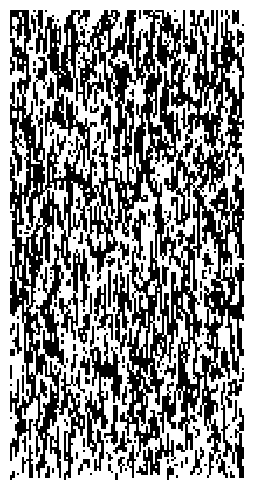

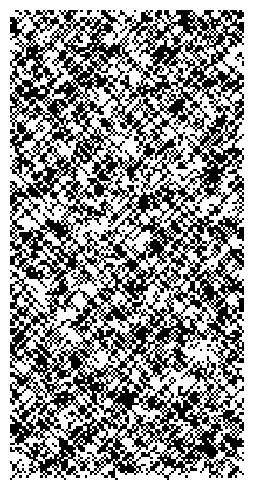

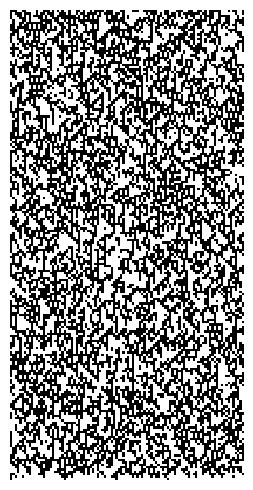

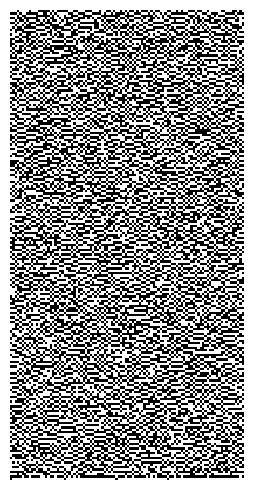

None None None None


In [19]:
system_1 = probabilistic_block_dynamics([0,45,67,23], 100, identity_n, 200, 0.2)
system_2 = probabilistic_block_dynamics([0,45,67,23], 100, swap2, 200, 0.2)
system_3 = probabilistic_block_dynamics([0,45,67,23], 100, xor_into_first, 200, 0.2)
system_4 = probabilistic_block_dynamics([0,45,67,23], 100, not_both, 200, 0.2)

print(plot_grid(system_1), plot_grid(system_2), plot_grid(system_3), plot_grid(system_4))

### 4.3.2) Dynamics of probabilistic block CA with matrices
We will now build some auxiliary fucntions to later deifne the dynamics of probabilistic block dynamics in terms of matrix-vector multiplication:

In [24]:
# compute necessary functions: noisy layer matrix eventually
def flip_matrix(probability):
    """Single-cell noise: flips with probability q. Column-stochastic."""
    q = probability
    return np.array([[1 - q, q],
                     [q, 1 - q]])

def noisy_layer_matrix(block_map, L, offset, probability, b=2):
    """2^L x 2^L column-stochastic matrix of one noisy layer.
    M'[i, j] = P(configuration j -> configuration i)."""
    assert L % b == 0, "L must be divisible by b"
    P = sp.csr_matrix(noisy_block_matrix(block_map, probability, b))
    K = P
    for _ in range(L // b - 1):
        K = sp.kron(K, P, format="csr")             # offset-0 layer
    r = _codes(np.roll(_bits(L), -offset, axis=1))  # state x -> roll(x, -offset)
    return K[r][:, r]

def noisy_block_matrix(block_map, probability, b=2):
    """P = B @ n^{⊗b}: noise on each cell first, then the block rule."""
    B = block_matrix(block_map, b).astype(float)
    n = flip_matrix(probability)
    N = n
    for _ in range(b - 1):
        N = np.kron(N, n)
    return B @ N


M = noisy_layer_matrix(swap2, L=2, offset=0, probability=0.1)
print(np.round(M.toarray(), 2))
print(np.allclose(M.sum(axis=0), 1))   # columns sum to 1

[[0.81 0.09 0.09 0.01]
 [0.09 0.01 0.81 0.09]
 [0.09 0.81 0.01 0.09]
 [0.01 0.09 0.09 0.81]]
True


In [25]:
def probabilistic_matrix_block_dynamics(initial_conditions, L, block_map, n_steps,
                                probability, b=2, rng=None):
    """Noisy block CA evolved with transition matrices.
    Returns a 0/1 grid with grid[0] = last step, matching dynamics()."""
    rng = np.random.default_rng() if rng is None else rng
    layers = [noisy_layer_matrix(block_map, L, o, probability, b).tocsc()
              for o in range(b)]
    X = _bits(L)

    x = np.zeros(L, dtype=int)
    x[np.asarray(initial_conditions, dtype=int)] = 1
    k = _codes(x)                                   # current configuration

    grid = np.empty((n_steps + 1, L), dtype=int)
    grid[0] = x
    for t in range(n_steps):
        col = layers[t % b][:, k]                   # where k can go, with probabilities
        k = rng.choice(col.indices, p=col.data)     # pick one
        grid[t + 1] = X[k]
    return grid[::-1]

In [26]:
print(probabilistic_matrix_block_dynamics([1,2,3], 8, swap2, 10, 0.5)[0])
print(probabilistic_matrix_block_dynamics([1,2,3], 8, swap2, 10, 0.5)[1])

[1 1 1 1 1 1 0 0]
[1 1 1 1 0 0 1 0]


### 4.3.3) Comparing the dynamics computed through the function and through matrix vector multiplication
As with the classical case, we have to make sure that both the original dynamics function and the dynamics with matrix-vector multiplication match. Nevertheless, we cannot take the appraoch taken with the classicla dynamics vecause the noise added makes it so that there may be cells that flip and others that do not, so it will most probably fail for most probabilities above zero. Instead, what we do is that both fucntions take the same pre-drawn flip mask, making each run deterministic and being able to be comoared exactly:

In [31]:
def probabilistic_block_dynamics_masks(initial_conditions, L, block_map, n_steps,
                                       flip_masks, block_size=2):
    """Original loop dynamics, with noise given by pre-drawn masks.
    flip_masks[t, i] = True -> cell i flips before the rule at step t."""
    b = block_size
    assert L % b == 0, "L must be divisible by block_size"

    state = np.zeros(L, dtype=int)
    state[np.asarray(initial_conditions, dtype=int)] = 1

    grid = np.empty((n_steps + 1, L), dtype=int)
    grid[0] = state

    for t in range(n_steps):
        state = np.where(flip_masks[t], 1 - state, state)     # noise first
        offset = t % b
        new_state = state.copy()
        for i in range(offset, L, b):
            idx = [(i + k) % L for k in range(b)]
            for pos, val in zip(idx, block_map(tuple(state[idx]))):
                new_state[pos] = val
        state = new_state
        grid[t + 1] = state

    return grid[::-1]


def matrix_block_dynamics_masks(initial_conditions, L, block_map, n_steps,
                                flip_masks, b=2):
    """Same dynamics via matrix-vector products on the one-hot state vector:
    v <- M_o F_m v, with F_m the permutation that flips the cells in mask m."""
    layers = [block_layer_matrix(block_map, L, o, b) for o in range(b)]
    X = _bits(L)
    idx = np.arange(2**L)

    x = np.zeros(L, dtype=int)
    x[np.asarray(initial_conditions, dtype=int)] = 1
    v = np.zeros(2**L, dtype=int)
    v[_codes(x)] = 1

    grid = np.empty((n_steps + 1, L), dtype=int)
    grid[0] = x
    for t in range(n_steps):
        m = _codes(flip_masks[t].astype(int))
        v = v[idx ^ m]                     # F_m @ v  (flip permutation)
        v = layers[t % b] @ v              # M_o @ v  (block rule)
        grid[t + 1] = X[np.argmax(v)]
    return grid[::-1]

The check is computed in this cell:

In [33]:
rules_by_b = {
    2: [identity_n, swap2, xor_into_first, not_both],
    3: [identity3, shift_right3, reverse3, toffoli, fredkin],
    4: [identity4, shift_right4, pair_swap4, toffoli4, rotate2x2],
}
L, n_steps, n_trials = 12, 40, 20
rng = np.random.default_rng(0)

for q in [0.0, 0.05, 0.3, 0.5]:
    print(f"=== q = {q} ===")
    for b, rules in rules_by_b.items():
        for rule in rules:
            ok = True
            for _ in range(n_trials):
                ic = np.flatnonzero(rng.integers(0, 2, L))
                masks = rng.random((n_steps, L)) < q          # shared noise
                g_direct = probabilistic_block_dynamics_masks(ic, L, rule, n_steps,
                                                              masks, block_size=b)
                g_matrix = matrix_block_dynamics_masks(ic, L, rule, n_steps,
                                                       masks, b=b)
                ok &= np.array_equal(g_direct, g_matrix)
            print(f"b={b} {rule.__name__:<15} {'OK' if ok else 'FAIL'}")


=== q = 0.0 ===
b=2 identity_n      OK
b=2 swap2           OK
b=2 xor_into_first  OK
b=2 not_both        OK
b=3 identity3       OK
b=3 shift_right3    OK
b=3 reverse3        OK
b=3 toffoli         OK
b=3 fredkin         OK
b=4 identity4       OK
b=4 shift_right4    OK
b=4 pair_swap4      OK
b=4 toffoli4        OK
b=4 rotate2x2       OK
=== q = 0.05 ===
b=2 identity_n      OK
b=2 swap2           OK
b=2 xor_into_first  OK
b=2 not_both        OK
b=3 identity3       OK
b=3 shift_right3    OK
b=3 reverse3        OK
b=3 toffoli         OK
b=3 fredkin         OK
b=4 identity4       OK
b=4 shift_right4    OK
b=4 pair_swap4      OK
b=4 toffoli4        OK
b=4 rotate2x2       OK
=== q = 0.3 ===
b=2 identity_n      OK
b=2 swap2           OK
b=2 xor_into_first  OK
b=2 not_both        OK
b=3 identity3       OK
b=3 shift_right3    OK
b=3 reverse3        OK
b=3 toffoli         OK
b=3 fredkin         OK
b=4 identity4       OK
b=4 shift_right4    OK
b=4 pair_swap4      OK
b=4 toffoli4        OK
b=4 rota

## 4.4) Spectral analysis of matrices for block CA
We have already looked at the general properties of markov chains and deterministic markov chains. As in Notebook 4 and 5, we aim to take a look at the markov chains corresponding to fully classical and probabilistic block CA and find their individual properties as well as give an interpretation to previous properties studied within the context of these CA.

We will first look at classical BCA and then their probabilistic counter-parts.

### 4.4.1) Classical block CA

In [ ]:
def block_period_matrix(block_map, L, b=2):
    T = block_layer_matrix(block_map, L, 0, b)       # step with offset 0
    for o in range(1, b):
        T = block_layer_matrix(block_map, L, o, b) @ T   # then offset 1, 2, …
    return T

print(type(block_period_matrix(swap2, 6, 2)))
print(block_period_matrix(swap2, 6, 2))

<class 'scipy.sparse._csr.csr_matrix'>
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 64 stored elements and shape (64, 64)>
  Coords	Values
  (0, 0)	1.0
  (1, 16)	1.0
  (2, 8)	1.0
  (3, 24)	1.0
  (4, 1)	1.0
  (5, 17)	1.0
  (6, 9)	1.0
  (7, 25)	1.0
  (8, 32)	1.0
  (9, 48)	1.0
  (10, 40)	1.0
  (11, 56)	1.0
  (12, 33)	1.0
  (13, 49)	1.0
  (14, 41)	1.0
  (15, 57)	1.0
  (16, 4)	1.0
  (17, 20)	1.0
  (18, 12)	1.0
  (19, 28)	1.0
  (20, 5)	1.0
  (21, 21)	1.0
  (22, 13)	1.0
  (23, 29)	1.0
  (24, 36)	1.0
  :	:
  (39, 27)	1.0
  (40, 34)	1.0
  (41, 50)	1.0
  (42, 42)	1.0
  (43, 58)	1.0
  (44, 35)	1.0
  (45, 51)	1.0
  (46, 43)	1.0
  (47, 59)	1.0
  (48, 6)	1.0
  (49, 22)	1.0
  (50, 14)	1.0
  (51, 30)	1.0
  (52, 7)	1.0
  (53, 23)	1.0
  (54, 15)	1.0
  (55, 31)	1.0
  (56, 38)	1.0
  (57, 54)	1.0
  (58, 46)	1.0
  (59, 62)	1.0
  (60, 39)	1.0
  (61, 55)	1.0
  (62, 47)	1.0
  (63, 63)	1.0


### 4.4.2) Probabilistic block CA